# PPO - LunarLander

The PPO implementation comes from Alexandr's branch, commit 85b15e4. Here we also check the saved model without exploration and compare it with the DQN.

In [1]:
import json
import time
from pathlib import Path

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

In [2]:
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

In [3]:
SEED=42
set_seed(SEED)

## Environment

In [4]:
def make_env(seed, render_mode=None):
    env = gym.make("LunarLander-v3", render_mode=render_mode)

    env.action_space.seed(seed)
    env.observation_space.seed(seed)
    return env

In [5]:
env = make_env(seed=SEED, render_mode=None)
state, info = env.reset(seed=SEED)
print(state)

[ 0.00229702  1.4181306   0.2326471   0.3204666  -0.00265488 -0.05269805
  0.          0.        ]


In [6]:
def get_end_reason(
        final_state,
        final_reward,
        terminated,
        truncated):
    if truncated:
        return "truncated"
    if not terminated:
        return "unknown"
    if final_reward > 0:
        return "at rest"
    if abs(final_state[0]) >= 1.0:
        return "out of bounds"
    return "crashed"

## Random agent

In [7]:
def run_random_agent(env, num_episodes, base_seed):
    episode_rewards = []
    episode_lenghts = []
    end_reasons = []

    env.action_space.seed(base_seed)

    for episode in range(num_episodes):
        state, info = env.reset(seed=base_seed + episode)
        terminated = False
        truncated = False
        total_reward = 0
        episode_steps = 0

        while not (terminated or truncated):
            action = env.action_space.sample()

            next_state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            episode_steps += 1
            state = next_state


        end_reason = get_end_reason(
            final_state = state,
            final_reward = reward,
            terminated = terminated,
            truncated = truncated
        )

        episode_rewards.append(total_reward)
        episode_lenghts.append(episode_steps)
        end_reasons.append(end_reason)


    return {
        "rewards": np.array(episode_rewards),
        "lengths": np.array(episode_lenghts),
        "end_reasons": end_reasons
    }

In [8]:
AGENT_EPISODES = 100

baseline_results = run_random_agent(env, num_episodes=AGENT_EPISODES, base_seed=SEED)

In [9]:
assert len(baseline_results["rewards"]) == AGENT_EPISODES
assert len(baseline_results["lengths"]) == AGENT_EPISODES
assert len(baseline_results["end_reasons"]) == AGENT_EPISODES


assert np.all(
    np.isfinite(baseline_results["rewards"])
)

assert np.all(
    baseline_results["lengths"] > 0
)

print("Baseline data is valid")

Baseline data is valid


In [10]:
baseline_rewards = baseline_results["rewards"]
baseline_lengths = baseline_results["lengths"]

print(
    f"Episodes: {AGENT_EPISODES}"
)

print(
    f"Mean reward: "
    f"{baseline_rewards.mean():.2f}"
)

print(
    f"Reward standard deviation: "
    f"{baseline_rewards.std():.2f}"
)

print(
    f"Minimum reward: "
    f"{baseline_rewards.min():.2f}"
)

print(
    f"Maximum reward: "
    f"{baseline_rewards.max():.2f}"
)

print(
    f"Mean episode length: "
    f"{baseline_lengths.mean():.2f}"
)

Episodes: 100
Mean reward: -174.82
Reward standard deviation: 102.74
Minimum reward: -461.57
Maximum reward: 22.31
Mean episode length: 89.54


In [11]:
from collections import Counter

reason_counts = Counter(
    baseline_results["end_reasons"]
)

print("End reasons:")

for reason, count in reason_counts.items():
    print(f"{reason}: {count}")

End reasons:
crashed: 91
out of bounds: 9


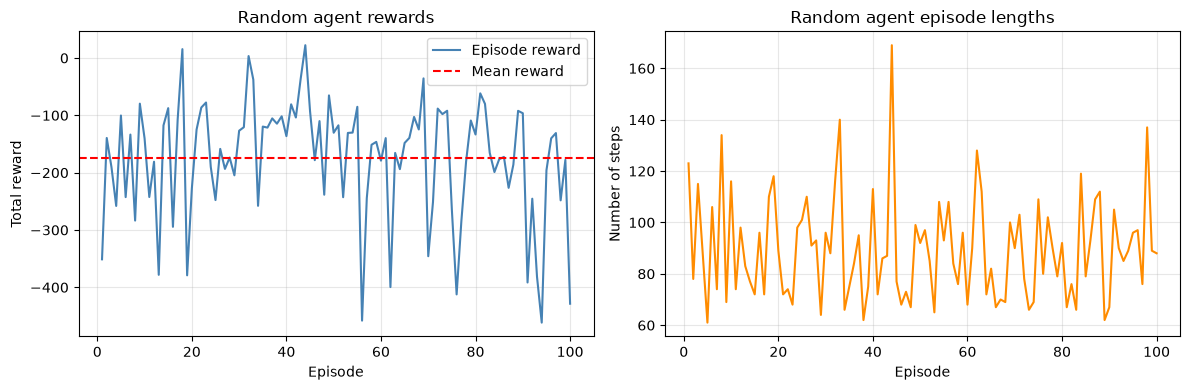

In [12]:
episodes = np.arange(1, AGENT_EPISODES + 1)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)

axes[0].plot(
    episodes,
    baseline_rewards,
    color="steelblue",
    label="Episode reward",
)

axes[0].axhline(
    baseline_rewards.mean(),
    color="red",
    linestyle="--",
    label="Mean reward",
)

axes[0].set_title("Random agent rewards")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Total reward")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    episodes,
    baseline_lengths,
    color="darkorange",
)

axes[1].set_title("Random agent episode lengths")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Number of steps")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Actor and critic

In [13]:
state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size)
print("Action size:", action_size)

State size: 8
Action size: 4


In [14]:
class ActorCritic(nn.Module):
    def __init__(self, state_size, action_size, hidden_size=64):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, action_size),
        )
        self.critic = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self,state):
        action_logits = self.actor(state)
        state_value = self.critic(state).squeeze(-1)
        return action_logits, state_value

    def get_action_and_value(
        self, state, action=None
    ):
        action_logits, state_value = self(state)

        distribution = Categorical(logits=action_logits)

        if action is None:
            action = distribution.sample()
        log_probability = distribution.log_prob(action)
        entropy = distribution.entropy()

        return (
            action, log_probability, entropy, state_value)

In [15]:
device = torch.device("cpu")

set_seed(SEED)

model = ActorCritic(
    state_size=state_size,
    action_size=action_size,
    hidden_size=64,
).to(device)

print(model)

ActorCritic(
  (actor): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
  (critic): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [16]:
state, info = env.reset(seed=SEED)

state_tensor = torch.as_tensor(
    state,
    dtype = torch.float32,
    device=device
).unsqueeze(0)


print("original state:", state.shape)
print("state tensor:", state_tensor.shape)

original state: (8,)
state tensor: torch.Size([1, 8])


In [17]:
with torch.no_grad():
    action, log_prob, entropy, state_value = (
        model.get_action_and_value(state_tensor)
    )

print("Action:", action.item())
print("Log probability:", log_prob.item())
print("Entropy:", entropy.item())
print("State value:", state_value.item())

Action: 0
Log probability: -1.4023222923278809
Entropy: 1.3858437538146973
State value: 0.14401426911354065


In [18]:
next_state, reward, terminated, truncated, info = env.step(action.item())

print("Next state:", next_state)
print("Reward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)

Next state: [ 0.00459394  1.424763    0.23233262  0.2947628  -0.00525882 -0.05208295
  0.          0.        ]
Reward: 1.1449803922348565
Terminated: False
Truncated: False


## Rollout storage

In [19]:
class RolloutStorage:
    def __init__(self):
        self.clear()

    def clear(self):
        self.states = []
        self.actions = []
        self.rewards = []
        self.next_states = []
        self.terminated = []
        self.truncated = []
        self.log_probs = []
        self.values = []

    def add(
        self,
        state,
        action,
        reward,
        next_state,
        terminated,
        truncated,
        log_prob,
        value
    ):
        self.states.append(state.copy())
        self.actions.append(action)
        self.rewards.append(reward)
        self.next_states.append(next_state.copy())
        self.terminated.append(terminated)
        self.truncated.append(truncated)
        self.log_probs.append(log_prob)
        self.values.append(value)
    def __len__(self):
        return len(self.rewards)

In [20]:
storage = RolloutStorage()

storage.add(
    state=state,
    action=action.item(),
    reward=reward,
    next_state=next_state,
    terminated=terminated,
    truncated=truncated,
    log_prob=log_prob.item(),
    value=state_value.item(),
)

assert len(storage) == 1
assert storage.states[0].shape == (state_size,)
assert storage.next_states[0].shape == (state_size,)
assert 0 <= storage.actions[0] < action_size

print("Transition stored correctly")

Transition stored correctly


## Collecting experiences

In [21]:
def state_to_tensor(state):
    return torch.tensor(
        state,
        dtype=torch.float32,
    ).unsqueeze(0)

def collect_rollout(
    env,
    model,
    storage,
    state,
    episode_reward,
    steps=256,
):
    storage.clear()
    finished_rewards = []

    for _ in range(steps):
        state_tensor = state_to_tensor(state)

        with torch.no_grad():
            action, log_prob, entropy, value = (
                model.get_action_and_value(state_tensor)
            )

        next_state, reward, terminated, truncated, info = (
            env.step(action.item())
        )

        storage.add(
            state,
            action.item(),
            reward,
            next_state,
            terminated,
            truncated,
            log_prob.item(),
            value.item(),
        )

        episode_reward += reward
        state = next_state

        if terminated or truncated:
            finished_rewards.append(episode_reward)
            episode_reward = 0
            state, info = env.reset()

    return state, episode_reward, finished_rewards

In [22]:
storage = RolloutStorage()

state, info = env.reset(seed=SEED)
episode_reward = 0

state, episode_reward, episode_rewards = collect_rollout(
    env,
    model,
    storage,
    state,
    episode_reward,
    steps=256,
)

print("Collected steps:", len(storage))
print("Finished episodes:", len(episode_rewards))
print("Episode rewards:", episode_rewards)

Collected steps: 256
Finished episodes: 2
Episode rewards: [np.float64(-115.83061972350029), np.float64(-150.10489621045699)]


In [23]:
states = torch.tensor(
    np.array(storage.states)
)

actions = torch.tensor(storage.actions)
rewards = torch.tensor(storage.rewards)

next_states = torch.tensor(
    np.array(storage.next_states)
)

terminated = torch.tensor(storage.terminated)
truncated = torch.tensor(storage.truncated)
old_log_probs = torch.tensor(storage.log_probs)
values = torch.tensor(storage.values)

print(states.dtype)
print(actions.dtype)
print(rewards.dtype)
print(terminated.dtype)

torch.float32
torch.int64
torch.float64
torch.bool


## Advantages with GAE

In [24]:
def compute_gae(
    model,
    rewards,
    values,
    next_states,
    terminated,
    truncated,
    gamma=0.99,
    gae_lambda=0.95,
):
    with torch.no_grad():
        _, next_values = model(next_states)

    advantages = torch.zeros_like(rewards)
    gae = 0.0

    for t in reversed(range(len(rewards))):
        bootstrap_mask = 1.0 - terminated[t].float()

        continue_mask = 1.0 - (
            terminated[t] | truncated[t]
        ).float()

        delta = (
            rewards[t]
            + gamma * bootstrap_mask * next_values[t]
            - values[t]
        )

        gae = (
            delta
            + gamma
            * gae_lambda
            * continue_mask
            * gae
        )

        advantages[t] = gae

    returns = advantages + values

    return advantages, returns

In [25]:
advantages, returns = compute_gae(
    model=model,
    rewards=rewards,
    values=values,
    next_states=next_states,
    terminated=terminated,
    truncated=truncated,
)

In [26]:
print("Advantages:", advantages.shape)
print("Returns:", returns.shape)

print("First advantages:", advantages[:5])
print("First returns:", returns[:5])

Advantages: torch.Size([256])
Returns: torch.Size([256])
First advantages: tensor([ -4.6192,  -7.1240,  -9.1389, -11.2604,  -6.6868], dtype=torch.float64)
First returns: tensor([ -4.4752,  -6.9781,  -8.9929, -11.1143,  -6.5413], dtype=torch.float64)


## PPO loss

In [27]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0003,
)

_, new_log_probs, entropy, new_values = (
    model.get_action_and_value(
        states,
        actions,
    )
)

ratio = torch.exp(
    new_log_probs - old_log_probs
)

clipped_ratio = torch.clamp(
    ratio,
    0.8,
    1.2,
)

policy_loss = -torch.min(
    ratio * advantages,
    clipped_ratio * advantages,
).mean()

value_loss = (
    (new_values - returns) ** 2
).mean()

loss = (
    policy_loss
    + 0.5 * value_loss
    - 0.01 * entropy.mean()
)

optimizer.zero_grad()
loss.backward()

torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    0.5
)
optimizer.step()

print("Policy loss:", policy_loss.item())
print("Value loss:", value_loss.item())
print("Total loss:", loss.item())

Policy loss: 21.316207350468268
Value loss: 1024.2249962650167
Total loss: 533.4148521146273


## Training

We run the existing 500 updates of 256 steps. The learning code is unchanged. We record the time on one CPU thread for the comparison.

In [28]:
training_start = time.perf_counter()
TRAINING_UPDATES = 500
PPO_EPOCHS = 4

all_rewards = []
storage = RolloutStorage()

for update in range(TRAINING_UPDATES):

    state, episode_reward, episode_rewards = collect_rollout(
        env,
        model,
        storage,
        state,
        episode_reward,
        steps=256,
    )

    all_rewards.extend(episode_rewards)


    states = torch.tensor(
        np.array(storage.states)
    )

    actions = torch.tensor(storage.actions)
    rewards = torch.tensor(storage.rewards)

    next_states = torch.tensor(
        np.array(storage.next_states)
    )

    terminated = torch.tensor(storage.terminated)
    truncated = torch.tensor(storage.truncated)
    old_log_probs = torch.tensor(storage.log_probs)
    values = torch.tensor(storage.values)


    advantages, returns = compute_gae(
        model=model,
        rewards=rewards,
        values=values,
        next_states=next_states,
        terminated=terminated,
        truncated=truncated,
    )

    advantages = (
        advantages - advantages.mean()
    ) / (
        advantages.std() + 1e-8
    )


    for epoch in range(PPO_EPOCHS):
        _, new_log_probs, entropy, new_values = (
            model.get_action_and_value(
                states,
                actions,
            )
        )

        ratio = torch.exp(
            new_log_probs - old_log_probs
        )

        clipped_ratio = torch.clamp(
            ratio,
            0.8,
            1.2,
        )

        policy_loss = -torch.min(
            ratio * advantages,
            clipped_ratio * advantages,
        ).mean()

        value_loss = (
            (new_values - returns) ** 2
        ).mean()

        loss = (
            policy_loss
            + 0.5 * value_loss
            - 0.01 * entropy.mean()
        )

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            0.5,
        )

        optimizer.step()

    if (update + 1) % 10 == 0:
        recent_rewards = all_rewards[-20:]

        if recent_rewards:
            mean_reward = np.mean(recent_rewards)
        else:
            mean_reward = 0

        print(
            f"Update {update + 1}, "
            f"mean reward: {mean_reward:.2f}, "
            f"loss: {loss.item():.2f}"
        )

ppo_training_seconds = time.perf_counter() - training_start
Path("results").mkdir(exist_ok=True)
ppo_training = {
    "seed": SEED, "steps": TRAINING_UPDATES * 256 + 256,
    "training_seconds": ppo_training_seconds,
    "scores": [float(score) for score in all_rewards],
    "source_commit": "85b15e4", "cpu_threads": 1,
}
Path("results/ppo_training.json").write_text(json.dumps(ppo_training, indent=2))
print(f"PPO training time: {ppo_training_seconds:.1f} seconds")

Update 10, mean reward: -187.96, loss: 1033.65


Update 20, mean reward: -202.12, loss: 407.88


Update 30, mean reward: -168.43, loss: 851.87


Update 40, mean reward: -149.96, loss: 634.97


Update 50, mean reward: -180.35, loss: 633.06


Update 60, mean reward: -206.59, loss: 549.62


... (40 outputs left out)

Update 470, mean reward: -40.99, loss: 291.86


Update 480, mean reward: -37.79, loss: 55.46


Update 490, mean reward: -49.88, loss: 176.38


Update 500, mean reward: -53.14, loss: 120.68
PPO training time: 55.0 seconds


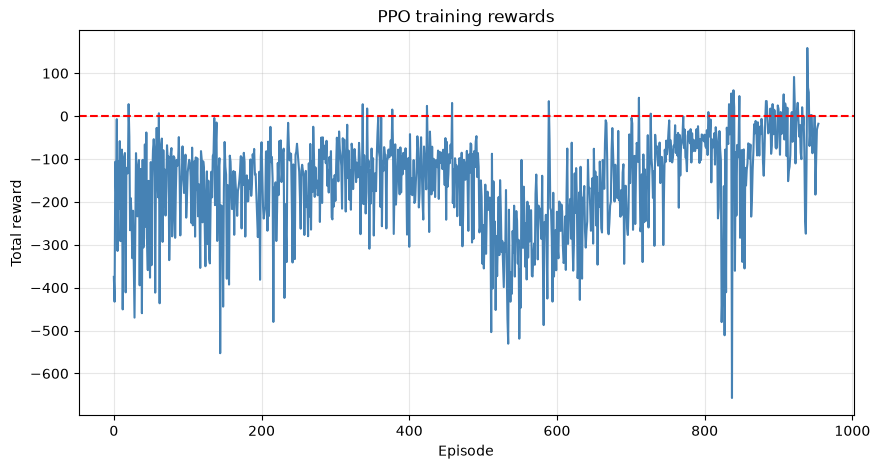

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    all_rewards,
    color="steelblue",
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
)

plt.title("PPO training rewards")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.grid(alpha=0.3)

plt.show()

## Evaluation

The original evaluation sampled actions. Here we choose the highest actor output, as required for evaluation without exploration.

In [30]:
def evaluate_agent(env, model, episodes=20):
    rewards = []

    for episode in range(episodes):
        state, info = env.reset(seed=SEED + episode)
        total_reward = 0
        finished = False

        while not finished:
            state_tensor = state_to_tensor(state)

            with torch.no_grad():
                action_logits, state_value = model(state_tensor)
                action = action_logits.argmax(dim=-1)

            action = action.item()

            state, reward, terminated, truncated, info = (
                env.step(action)
            )

            total_reward += reward
            finished = terminated or truncated

        rewards.append(total_reward)

    return np.array(rewards)

In [31]:
evaluation_rewards = evaluate_agent(
    env,
    model,
    episodes=20,
)

print("Mean reward:", evaluation_rewards.mean())
print("Minimum reward:", evaluation_rewards.min())
print("Maximum reward:", evaluation_rewards.max())

Mean reward: -429.03569941849275
Minimum reward: -509.5075213427397
Maximum reward: -374.72343074232566


## Saving the model

This rerun writes models/ppo_reproduced.pt. The main ppo_lunar_lander.pt file is the checkpoint from Alexandr's commit 85b15e4.

In [32]:
Path("models").mkdir(exist_ok=True)
torch.save(
    model.state_dict(),
    "models/ppo_reproduced.pt",
)

print("Model saved")

Model saved


In [33]:
evaluation_rewards = evaluate_agent(
    env,
    model,
    episodes=100,
)

print("Mean reward:", evaluation_rewards.mean())
print("Standard deviation:", evaluation_rewards.std())
print("Minimum reward:", evaluation_rewards.min())
print("Maximum reward:", evaluation_rewards.max())
print(
    "Episodes above 200:",
    np.sum(evaluation_rewards >= 200),
)

Mean reward: -426.7150088627508
Standard deviation: 33.723409938869715
Minimum reward: -509.5075213427397
Maximum reward: -312.8033518547751
Episodes above 200: 0


## Held-out evaluation

We test the weights from this rerun over 100 consecutive episodes for each seed range. These starts are separate from training. The actor always chooses the highest output, so there is no action sampling.

The result file keeps every score, episode length and ending for the comparison.

In [34]:
def evaluate_saved_ppo(model, episodes, seed):
    test_env = gym.make("LunarLander-v3", render_mode=None)
    results = {"scores": [], "lengths": [], "endings": []}
    try:
        with torch.no_grad():
            for episode in range(episodes):
                state, info = test_env.reset(seed=seed + episode)
                score = 0.0
                steps = 0
                done = False
                while not done:
                    values = model.actor(torch.tensor(state, dtype=torch.float32))
                    state, reward, terminated, truncated, info = test_env.step(values.argmax().item())
                    score += reward
                    steps += 1
                    done = terminated or truncated
                if not test_env.unwrapped.lander.awake:
                    reason = "at rest"
                elif test_env.unwrapped.game_over:
                    reason = "crash"
                elif abs(state[0]) >= 1:
                    reason = "out of bounds"
                else:
                    reason = "time limit"
                results["scores"].append(score)
                results["lengths"].append(steps)
                results["endings"].append(reason)
    finally:
        test_env.close()
    return results


from model import load_model

reproduced_model = load_model("ppo", "models/ppo_reproduced.pt")
ppo_final = {}
for seed in [20_000, 30_000, 40_000]:
    test = evaluate_saved_ppo(reproduced_model, 100, seed)
    ppo_final[str(seed)] = test
    print(f"Test seed {seed}: mean = {np.mean(test['scores']):.2f}, "
          f"std = {np.std(test['scores']):.2f}")
    for reason in ["crash", "out of bounds", "at rest", "time limit"]:
        print(f"  {reason}: {test['endings'].count(reason)}")
Path("results/ppo_reproduced.json").write_text(json.dumps(ppo_final, indent=2))
env.close()

Test seed 20000: mean = -426.84, std = 28.21
  crash: 0
  out of bounds: 36
  at rest: 0
  time limit: 64


Test seed 30000: mean = -427.33, std = 31.16
  crash: 0
  out of bounds: 30
  at rest: 0
  time limit: 70


Test seed 40000: mean = -429.69, std = 25.37
  crash: 0
  out of bounds: 33
  at rest: 0
  time limit: 67


## Comparing with DQN

We also evaluate the PPO checkpoint from commit 85b15e4, which is the main file used by model.py. The rerun above is kept separately because its scores differ from that checkpoint.

All final comparisons use the same 100 episodes per seed range, without exploration. DQN chooses the highest Q-value. PPO chooses the highest actor output.

Original PPO, test seed 20000: mean = -212.12, std = 28.03


Original PPO, test seed 30000: mean = -213.88, std = 26.41


Original PPO, test seed 40000: mean = -216.17, std = 25.91
DQN, seed 20000: {'mean': 247.553197041104, 'std': 51.587418332539606}
DQN, seed 30000: {'mean': 253.59329898623858, 'std': 56.244270471511655}
DQN, seed 40000: {'mean': 253.2902196001731, 'std': 47.46380413744933}
PPO original, seed 20000: {'mean': -212.12243418412032, 'std': 28.03414512844415}
PPO original, seed 30000: {'mean': -213.8816406476049, 'std': 26.411175249325048}
PPO original, seed 40000: {'mean': -216.16835924562503, 'std': 25.912262773989497}
PPO rerun, seed 20000: {'mean': -426.8350931306702, 'std': 28.212395284123478}
PPO rerun, seed 30000: {'mean': -427.333938785744, 'std': 31.16405538053848}
PPO rerun, seed 40000: {'mean': -429.6933907959194, 'std': 25.374653988342544}


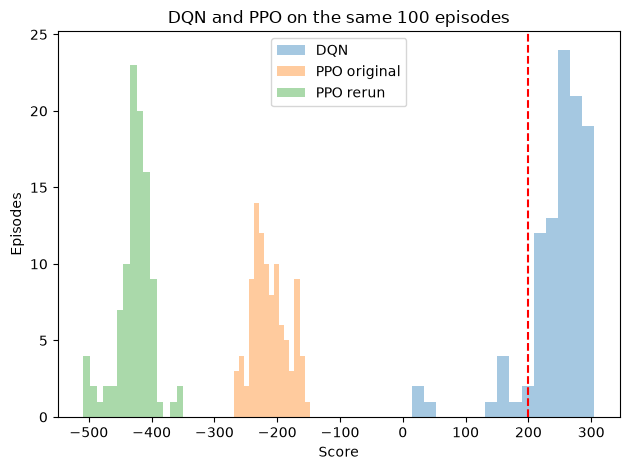

In [35]:
original_ppo = load_model("ppo", "ppo_lunar_lander.pt")
original_results = {}
for seed in [20_000, 30_000, 40_000]:
    test = evaluate_saved_ppo(original_ppo, 100, seed)
    original_results[str(seed)] = test
    print(f"Original PPO, test seed {seed}: mean = {np.mean(test['scores']):.2f}, "
          f"std = {np.std(test['scores']):.2f}")
Path("results/ppo_final.json").write_text(json.dumps(original_results, indent=2))

dqn_results = json.loads(Path("results/dqn_final.json").read_text())
comparison = {}
for name, results in [("DQN", dqn_results), ("PPO original", original_results), ("PPO rerun", ppo_final)]:
    comparison[name] = {}
    for seed, test in results.items():
        comparison[name][seed] = {
            "mean": float(np.mean(test["scores"])),
            "std": float(np.std(test["scores"])),
        }
        print(f"{name}, seed {seed}: {comparison[name][seed]}")
    plt.hist(results["20000"]["scores"], bins=15, alpha=0.4, label=name)
Path("results/comparison.json").write_text(json.dumps(comparison, indent=2))
plt.axvline(200, color="red", linestyle="--")
plt.xlabel("Score")
plt.ylabel("Episodes")
plt.title("DQN and PPO on the same 100 episodes")
plt.legend()
plt.tight_layout()
plt.show()

## Comparison and conclusion

| Model | Mean, test seed 20000 | Std | Training steps | Training seconds |
| --- | ---: | ---: | ---: | ---: |
| DQN, lr 0.0005 | 247.55 | 51.59 | 300155 | 365.7 |
| PPO, original checkpoint | -212.12 | 28.03 | Not recorded with file | Not recorded |
| PPO, same-code rerun | -426.84 | 28.21 | 128256 | 55.0 |

The DQN reaches a mean of at least 200 in all three final seed ranges. The current PPO checkpoint and our rerun do not reach it. Their small standard deviation comes from consistently low scores, so it is not a sign of good landings.

The selected DQN first passes 200 on a small validation test after 190,420 steps. Its curves still go up and down, which is why we keep the best checkpoint. PPO has not reached the target by the end of this 128,256-step rerun.

The budgets differ, and the PPO checkpoint from the branch has no recorded training time. We report the rerun's time separately. We cannot use these runs to claim that DQN is always more efficient or faster than PPO.

The earlier PPO evaluation sampled actions. Choosing the highest actor output changes its behaviour and exposes a failure of the current policy. More training and regular evaluation without sampling are needed before calling the PPO solved.

The DQN part is ready. The remaining PPO work includes its training-seed comparison, a variation experiment, fuller training logs and a model that reaches the target.